Types of data used for I/O:
-> Text - '12345' as a seq of unicode chars (Every string in python is a unicode char)
-> Binary - 12345 as a seq of bytes of its binary eq

Hence there are 2 types : -
-> Text files
-> Binary files (Images, music, video etc.)

Writing to a file: -

In [ ]:
#Case 1: - If file is not present
f = open('Sample.txt', 'w')     #open('address', 'mode')
f.write('Hello world')

f.close()

#This creates a new file named Sample.txt in the same directory as this python file.
#Once we close the file, we cant do anything. We have to open it again to work

f.write("hello")

ValueError: I/O operation on closed file.

In [ ]:
#Write multiline strings
f = open('sample1.txt', 'w')
f.write('hello world')
f.write('\nThis is file handling')
f.close()

22

In [ ]:
#Case 2 - If file is already present.
f = open("Sample.txt", 'w')
f.write("This is existing file")
f.close()

#As Sample.txt already exists, hence the write overwrites the content in the file

In [ ]:
#What does open() do?
#So the files are actually present in the ROM. So this open fetches the files to Buffer memory where the file is read. After the file is closed, it goes back to the ROM.

In [12]:
#Append mode
f = open('sample1.txt', 'a')
f.write('\nHi again')
f.close()

In [8]:
#Write multiple lines
L = ['Hello\n', 'How are you?\n', 'I am great!']
f = open('Sample.txt', 'w')
f.writelines(L)     #To write multiple lines
f.close()

Read from file: -

In [1]:
f = open('Sample.txt', 'r')
print(f.read())
f.close()

Hello
How are you?
I am great


In [ ]:
#reading n chars
f = open('Sample.txt', 'r')
print(f.read(10))       #Only reads 10 chars
f.close()

Hello
How 


In [ ]:
#Read line by line
f = open('Sample.txt', 'r')
print(f.readline())
print(f.readline())
f.close()

#Read line atomatically changes the line, same as print, so they give 1 extra line gap.

Hello

How are you?



In [5]:
#Reading entire using readline
f = open('Sample.txt', 'r')

while True:
    data = f.readline()
    if data == "":
        break
    else:
        print(data, end='')

f.close()

Hello
How are you?
I am great

Using Context manager (with):-
-> with keyword closes the file as soon as the usage is over.

In [7]:
with open('sample1.txt', 'w') as f:
    f.write('Helloooo!!!')

#Here it automatically closes the file.

In [ ]:
#moving within file -> 10 char then 10 char
with open('Sample.txt', 'r') as f:
    print(f.read(10))   #prints first 10 chars
    print(f.read(10))   #prints next 10 chars

Hello
How 
are you?
I


In [ ]:
#To load a big file in memory
big_List = ['hello world' for i in range(1000)]
with open('bigFile.txt', 'w') as f:
    f.writelines(big_List)  #gives a file having hello world 1000 times

In [ ]:
with open('bigFile.txt', 'r') as f:

    chunk_size = 100
    while len(f.read(chunk_size))>0:
        print(f.read(chunk_size))   #prints 100 chars
        f.read(chunk_size)  #loads next 100 chars

ello worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhe
o worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello
orldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello wo
dhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello world
llo worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhel
 worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello 
rldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello wor
hello worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldh
lo worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhell
worldhello worldhello worldhello worldhello worldhello worldhello worldhello worldhello wor

In [ ]:
#Seek and Tell functions

with open('Sample.txt', 'r') as f:
    print(f.read(10))   
    print(f.tell())     #Tells us where the buffer pos is.
    f.seek(0)       #Moves our buffer to the assigned location.
    print(f.tell())
    print(f.read(10))   #Again buffer starts from 0 and prints 10 chars.

Hello
How 
10
0
Hello
How 


In [18]:
#Seek during write mode
with open('Sample.txt', 'w') as f:
    f.write('Hello')
    f.seek(0)
    f.write('Hi World')
    f.seek(0)
    f.write('X')

Problems with text mode: -
-> cant work on binary files like images
-> not good for data types like int/float/list etc

Binary Files: -

In [ ]:
#working with binary files: -
with open('Mark.jpg', 'r') as f:
    f.read()

#This only works for unicode chars(Strings)

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte

In [ ]:
with open('Mark.jpg', 'rb') as f: #rb is read binary
    with open('Mark_borja.jpg', 'wb') as wf:
        wf.write(f.read())

#Here we are creating an exact copy of the image.
#Here the new file is Mark_borja.jpg

In [21]:
#Working with big binary files: -
with open('Sample.txt', 'w') as f:
    f.write(5)

#This throws an error as here 5 is not a unicode char(string). It is int

TypeError: write() argument must be str, not int

In [27]:
#more complex data 
d = {
    'name' : 'Nikhil',
    'age' : 33,
    'gender' : 'Male'
}

# with open('Sample.txt', 'w') as f:
#     f.write(d)

#This too throws an error as it is not unicode char.

with open('Sample.txt', 'w') as f:
     f.write(str(d))

with open('Sample.txt', 'r') as f:
     print(f.read())        #But this is a string, even though it looks like a dict.
     print(type(f.read()))

{'name': 'Nikhil', 'age': 33, 'gender': 'Male'}
<class 'str'>


Serialization and Deserialization: -

-> Serialization : - Process of converting python datatypes tp JSON(JavaScript On Notation) format.(Understood by all programming languages)
-> Deserialization: - JSON -> datatypes

Serialization: -
json.dump(what_to_dump, file_handler_object)

In [25]:
#List : -
import json
L = [1, 2, 3, 4]

with open ('demo.json', 'w') as f:
    json.dump(L, f)         #json.dump(what_to_dump, file_handler_object)


In [26]:
#Dictionary: -
d = {
    'name' : 'Nikhil',
    'age' : 33,
    'gender' : 'Male'
}

with open('demo.json', 'w') as f:
    json.dump(d, f)

Deserialization: -
json.load(file_handler_object)

In [ ]:
import json 
with open('demo.json', 'r') as f:
    d = json.load(f)
    print(d)
    print(type(d))      #Gives dict datatype, not string.

{'name': 'Nikhil', 'age': 33, 'gender': 'Male'}
<class 'dict'>


In [ ]:
#serialization and deserialize tuple: - 
import json

t = (1, 2, 3, 4, 5)
with open('demo.json', 'w') as f:
    json.dump(t, f)
    #When we dump tuple, it gets stored as a list. And when we deserialize it, we get a list only.

In [30]:
#Nested Dict
d = {
    'student' : 'Nikhil',
    'marks' : [18, 22, 26, 33, 34, 33, 35]
}

with open('demo.json', 'w') as f:
    json.dump(d, f)

Serializing and Deserializing custom objects: -

In [ ]:
class Person:

    def __init__(self, fname, lname, age, gender):
        self.fname = fname
        self.lname = lname
        self.age = age
        self.gender = gender


#format to be printed()
# -> Sai Nikhil age -> 19 gender -> male

In [32]:
person = Person('Sai', 'Nikhil', 18, 'Male')

In [33]:
import json

def show_obj(person):
    if isinstance(person, Person):
        return f"{person.fname} {person.lname} age -> {person.age} gender -> {person.gender}"

with open('demo.json', 'w') as f:
    # json.dump(person, f)          This gives an error
    json.dump(person, f, default=show_obj)
    #That default tells our json on how to show the object

In [34]:
#Deserializing: -
import json

with open('demo.json', 'r') as f:
    print(json.load(f))

Sai Nikhil age -> 18 gender -> Male


Pickling: - (Used in machine learning models)(.pkl extension)

pickling: - The process whereby a Python object(class - object) hierarchy is converted into byte stream(Binary file or bytes like object).

unpickling: - Reverse process of pickling

In [35]:
class Person:

    def __init__(self, name, age):
        self.name = name
        self.age = age

    def display_info(self):
        print(f'Hi, my name is {self.name}. I am {self.age} years old.')

In [36]:
p = Person('Nikhil', 19)

In [37]:
#pickle dump
import pickle
with open('person.pkl', 'wb') as f:     #Have to open in wb mode(binary write)
    pickle.dump(p, f)

In [ ]:
#pickle load
import pickle
with open('person.pkl', 'rb') as f:
    p = pickle.load(f)       #p has the address of the object(Works as a reference variable).

p.display_info()

Hi, my name is Nikhil. I am 19 years old.


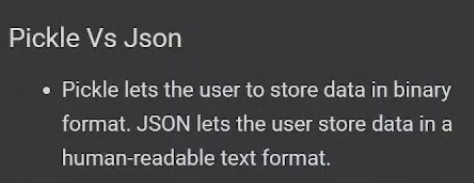